# Municípios e estados do Brasil: exploratory analysis

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Works in the repository (data/) and on Kaggle (/kaggle/input/...)
candidates = [Path.cwd() / 'data', Path.cwd().parent / 'data']
candidates += [p.parent for p in Path('/kaggle/input').glob('**/municipios.parquet')]
data = next(p for p in candidates if (p / 'municipios.parquet').exists())
cities = pd.read_parquet(data / 'municipios.parquet')
states = pd.read_parquet(data / 'estados.parquet')
print(cities.shape, states.shape)

(5570, 15) (27, 14)


## Every municipal seat, coloured by IANA time zone

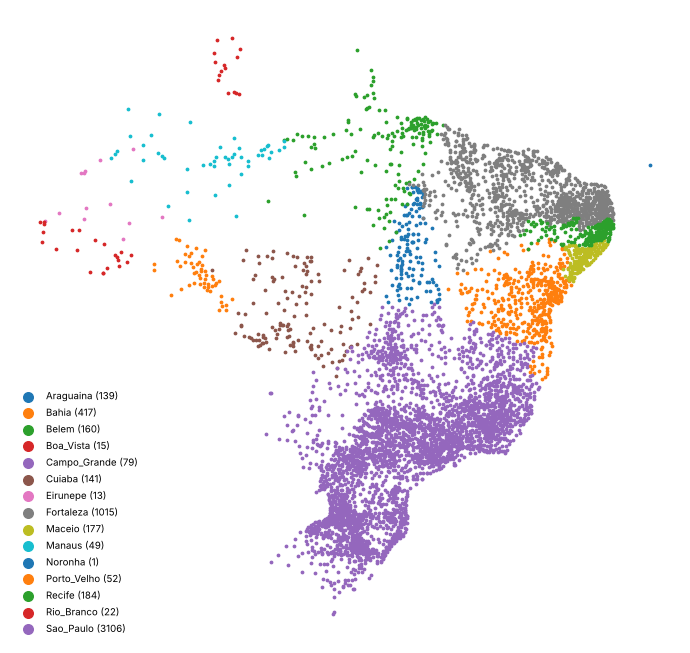

In [2]:
fig, ax = plt.subplots(figsize=(7, 7))
for zone, group in cities.groupby('timezone'):
    ax.scatter(group['longitude'], group['latitude'], s=3, label=f"{zone.split('/')[1]} ({len(group)})")
ax.set_aspect('equal')
ax.axis('off')
ax.legend(markerscale=4, fontsize=7, loc='lower left', frameon=False)
plt.tight_layout()

## Municipalities per region and state

In [3]:
cities.groupby(['region', 'uf']).size().unstack(0).fillna(0).astype(int).sum().sort_values(ascending=False)

region
Nordeste        1794
Sudeste         1668
Sul             1191
Centro-Oeste     467
Norte            450
dtype: int64

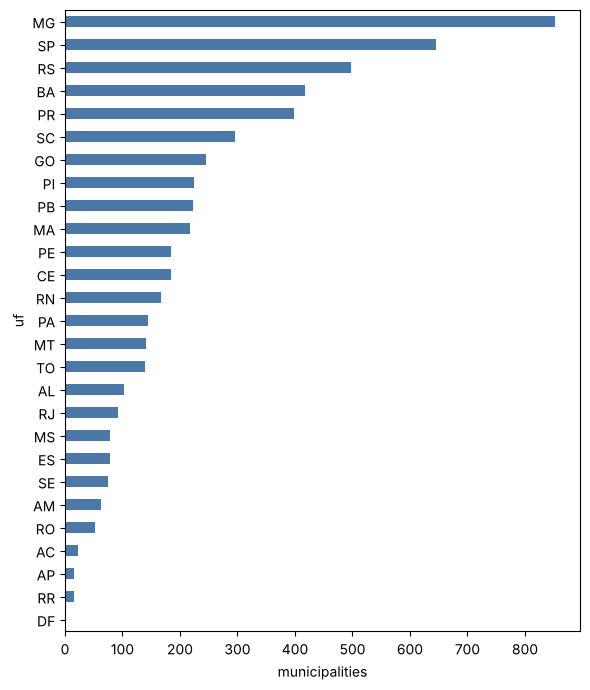

In [4]:
ax = cities['uf'].value_counts().sort_values().plot.barh(figsize=(6, 7), color='#4C78A8')
ax.set_xlabel('municipalities')
plt.tight_layout()

## Area codes (DDD) that cover the most municipalities

In [5]:
cities.groupby('ddd').agg(municipios=('ibge_code', 'size'), ufs=('uf', lambda s: ', '.join(sorted(set(s))))).nlargest(10, 'municipios')

,municipios,ufs
ddd,,
83,223,PB
33,175,MG
84,167,RN
55,160,RS
35,159,MG
51,157,RS
54,155,RS
49,150,"PR, SC"
75,143,BA


## UTC offsets

In [6]:
cities.groupby('utc_offset').agg(municipios=('ibge_code', 'size'), ufs=('uf', lambda s: ', '.join(sorted(set(s)))))

,municipios,ufs
utc_offset,,
-02:00,1,PE
-03:00,5198,"AL, AP, BA, CE, DF, ES, GO, MA, MG, PA, PB, PE..."
-04:00,336,"AM, MS, MT, RO, RR"
-05:00,35,"AC, AM"


## State grammar for text generation

In [7]:
for s in states.sort_values('name').itertuples():
    print(f"{s.uf}: Cartórios {s.name_with_em} | Prefeituras {s.name_with_de}")

AC: Cartórios no Acre | Prefeituras do Acre
AL: Cartórios em Alagoas | Prefeituras de Alagoas
AP: Cartórios no Amapá | Prefeituras do Amapá
AM: Cartórios no Amazonas | Prefeituras do Amazonas
BA: Cartórios na Bahia | Prefeituras da Bahia
CE: Cartórios no Ceará | Prefeituras do Ceará
DF: Cartórios no Distrito Federal | Prefeituras do Distrito Federal
ES: Cartórios no Espírito Santo | Prefeituras do Espírito Santo
GO: Cartórios em Goiás | Prefeituras de Goiás
MA: Cartórios no Maranhão | Prefeituras do Maranhão
MT: Cartórios no Mato Grosso | Prefeituras do Mato Grosso
MS: Cartórios no Mato Grosso do Sul | Prefeituras do Mato Grosso do Sul
MG: Cartórios em Minas Gerais | Prefeituras de Minas Gerais
PR: Cartórios no Paraná | Prefeituras do Paraná
PB: Cartórios na Paraíba | Prefeituras da Paraíba
PA: Cartórios no Pará | Prefeituras do Pará
PE: Cartórios em Pernambuco | Prefeituras de Pernambuco
PI: Cartórios no Piauí | Prefeituras do Piauí
RN: Cartórios no Rio Grande do Norte | Prefeituras d

## Most common municipality names (same name in several states)

In [8]:
cities['name'].value_counts().head(10)

name
Bom Jesus          6
São Domingos       5
Bonito             4
Santa Helena       4
Santa Inês         4
Santa Luzia        4
Vera Cruz          4
São Francisco      4
Planalto           4
Cruzeiro do Sul    3
Name: count, dtype: int64